In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
class GaussianRBFBasis1D:
    """
    1D Gaussian radial-basis-function (RBF) basis.

    This class defines a set of Gaussian basis functions with fixed centers (mus)
    and shared width (sigma). It provides methods to evaluate the basis and its
    derivative at given points, and simple plotting helpers.

    Attributes:
        sigma (float): Standard deviation (width) of the Gaussian bumps. Must be > 0.
        mus (np.ndarray): 1D array of centers of the Gaussians, shape (n,).
        n (int): Number of basis functions (len(mus)).
    """
    def __init__(self, sigmas, mus):
        self.sigmas = sigmas
        self.mus = mus
        self.n = mus.shape[1]
    
    def forward(self, x):
        """
        Evaluate the Gaussian RBFs at points x.

        Args:
            x (np.ndarray): 1D array of evaluation points, shape (n_points,).

        Returns:
            np.ndarray: Matrix of basis values, shape (n,n_points),
                        where column row is exp(-0.5 * ((x - mus[j]) / sigma)**2).
        """
        basis_values = np.exp(-0.5 * ((x[None, None, :] - self.mus[:, :, None]) / self.sigmas[:,None,None]) ** 2)
        return basis_values
    
    def grad(self, x):
        """
        Compute derivative of each Gaussian basis function w.r.t. x.

        Args:
            x (np.ndarray): 1D array of evaluation points, shape (n_points,).

        Returns:
            np.ndarray: Matrix of basis derivatives, shape (n,n_points).
        """
        basis_gradients = -((x[None, None, :]  - self.mus[:, :, None]) / (self.sigmas[:,None,None] ** 2)) * self.forward(x)
        return basis_gradients
    
    def laplacian(self, x):
        """
        Compute second derivative (Laplacian) of each Gaussian basis function w.r.t. x.

        Args:
            x (np.ndarray): 1D array of evaluation points, shape (n_points,).

        Returns:
            np.ndarray: Matrix of basis second derivatives, shape (n,n_points).
        """
        basis_laplacians = (((x[None, None, :] - self.mus[:, :, None]) ** 2) / (self.sigmas[:,None,None] ** 4) - 1 / (self.sigmas[:,None,None] ** 2)) * self.forward(x)
        return basis_laplacians

    def plot_1d_basis(self):
        resolution = 1000
        x_values = np.linspace(0, 1, resolution)  # Adjusted range for x_values
        basis_matrix = self.forward(x_values)[0]
        print(basis_matrix.shape)
        plt.figure(figsize=(8, 6))
        for i in range(self.n):
            plt.plot(x_values, basis_matrix[i,:], label=f'Basis {i}')
        plt.title(f'1D Basis Functions')
        plt.xlabel('x')
        plt.ylabel('Basis Values')
        plt.legend()
        plt.grid(True)
        plt.show()
        
    def plot_1d_basis_gradients(self):
        resolution = 1000
        x_values = np.linspace(0, 1, resolution)  # Use full knot span for x_values
        basis_gradients_matrix = self.grad(x_values)[0]
        plt.figure(figsize=(8, 6))
        for i in range(self.n):
            plt.plot(x_values, basis_gradients_matrix[i,:], label=f'Gradient {i}')
        plt.title(f'Gradients of 1D Basis Functions')
        plt.xlabel('x')
        plt.ylabel('Gradient Values')
        plt.legend()
        plt.grid(True)
        plt.show()

(20, 1000)


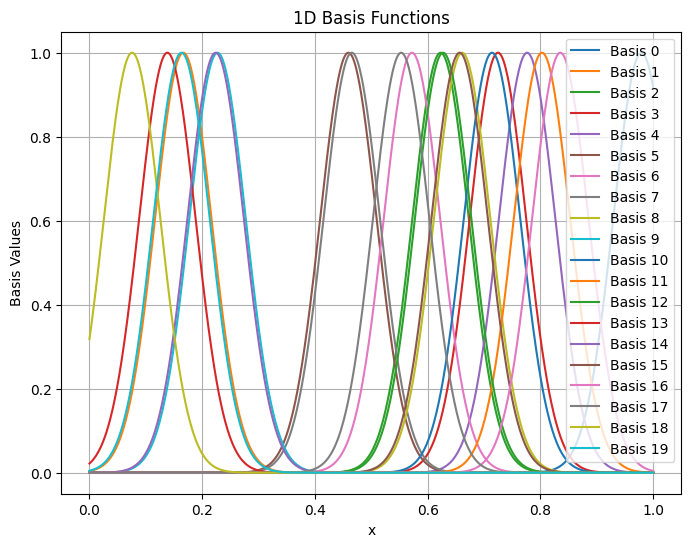

In [12]:
N_samples = 10
sigmas = 0.05*np.ones(N_samples)
mus = np.random.uniform(0, 1, size=(N_samples,int(1/sigmas[0])))
basis = GaussianRBFBasis1D(sigmas=sigmas, mus=mus)
basis.plot_1d_basis() 

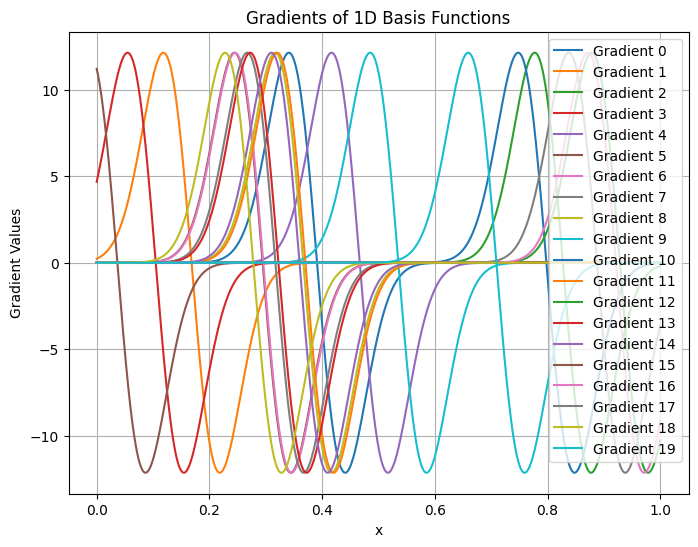

In [11]:
basis.plot_1d_basis_gradients()

In [8]:
x = np.linspace(0, 1, 100)
b_vals = basis.forward(x)
b_vals.shape

(10, 20, 100)